# Top Model Pairs — excluding vibe / mixture_of_gaussians — `results_model_pairs`

Reads the per-case pair tables produced by `run_model_experiments.py --pairs` (`<case>_pairs.csv`, one row per fast x slow model pair with its `fast_f1` and `slow_f1`), with **all pairs where the fast or slow model is `vibe` or `mixture_of_gaussians` removed** (`EXCLUDE_MODELS`) — i.e. only pairs whose *both* models are outside that list. Prints the top-5 remaining pairs per case and shows four image grids (busStation slow/fast, canoe slow/fast); each grid row is one frame - the input followed by the masks of the top-5 remaining models.

**Note on masks:** in the dual-rate pipeline the fast mask depends only on the fast model and the slow mask only on the slow model. The printed tables list the surviving pairs literally; the grids show the top-5 distinct **remaining models**, using each model's diagonal `M__M__<role>` mask, so no image repeats.

In [34]:
import glob
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS = Path('results_model_pairs')
DATA = Path('data_0_1fps')
CASES = ['busStation', 'canoe']
TOP_N = 5
QVGA = (320, 240)  # (width, height)
EXCLUDE_MODELS = ['vibe', 'mixture_of_gaussians']

pd.set_option('display.float_format', lambda v: f'{v:.4f}')


def load_pairs(case):
    """Load a case's pairs, dropping any pair that uses an EXCLUDE_MODELS model."""
    df = pd.read_csv(RESULTS / f'{case}_pairs.csv')
    keep = ~df['fast_model'].isin(EXCLUDE_MODELS) & ~df['slow_model'].isin(EXCLUDE_MODELS)
    return df[keep].reset_index(drop=True)


pair_tables = {case: load_pairs(case) for case in CASES}

## 1. Top-5 pairs per case

In [35]:
for case in CASES:
    table = pair_tables[case]
    print(f'{case} — top {TOP_N} pairs by fast_f1')
    display(table.sort_values('fast_f1', ascending=False).head(TOP_N).reset_index(drop=True))
    print(f'{case} — top {TOP_N} pairs by slow_f1')
    display(table.sort_values('slow_f1', ascending=False).head(TOP_N).reset_index(drop=True))

busStation — top 5 pairs by fast_f1


,fast_model,slow_model,fast_f1,slow_f1
0,running_gaussian,static_frame_difference,0.7261,0.6761
1,running_gaussian,eigenbackground,0.7261,0.0000
2,running_gaussian,running_gaussian,0.7261,0.6498
3,running_gaussian,frame_difference,0.7261,0.5531
4,running_gaussian,adaptive_median,0.7261,0.6761


busStation — top 5 pairs by slow_f1


,fast_model,slow_model,fast_f1,slow_f1
0,running_average,running_average,0.6608,0.6772
1,frame_difference,running_average,0.5516,0.6772
2,running_gaussian,running_average,0.7261,0.6772
3,adaptive_median,running_average,0.6770,0.6772
4,eigenbackground,running_average,0.0000,0.6772


canoe — top 5 pairs by fast_f1


,fast_model,slow_model,fast_f1,slow_f1
0,running_gaussian,static_frame_difference,0.7113,0.5945
1,running_gaussian,eigenbackground,0.7113,0.0000
2,running_gaussian,running_gaussian,0.7113,0.5379
3,running_gaussian,frame_difference,0.7113,0.6041
4,running_gaussian,adaptive_median,0.7113,0.5945


canoe — top 5 pairs by slow_f1


,fast_model,slow_model,fast_f1,slow_f1
0,running_average,frame_difference,0.6079,0.6041
1,static_frame_difference,frame_difference,0.5946,0.6041
2,running_gaussian,frame_difference,0.7113,0.6041
3,adaptive_median,frame_difference,0.5946,0.6041
4,eigenbackground,frame_difference,0.0000,0.6041


## 2. Query pairs by model

`query_pairs(fast=None, slow=None, case=None)`:

* no model given -> every pair with its `fast_f1`, `slow_f1`, `rank_fast`, `rank_slow`;
* both models given -> the single matching pair (one row per case);
* one model given -> all pairs where that model matched (as fast or slow).

Ranks are per case, dense, with 1 = best F1.

In [36]:
def rank_desc(series):
    """Dense rank (1 = highest F1) of a score column."""
    return series.rank(ascending=False, method='dense').astype(int)


def query_pairs(fast=None, slow=None, case=None):
    """Pairs with fast/slow F1 and their ranks, optionally filtered.

    Args:
        fast: keep only pairs with this fast model (None = any).
        slow: keep only pairs with this slow model (None = any).
        case: restrict to one case (None = both, tagged by a 'case' column).

    Returns:
        A DataFrame of case, fast_model, slow_model, fast_f1, slow_f1,
        rank_fast, rank_slow (ranks per case, 1 = best).
    """
    selected = [case] if case is not None else CASES
    frames = []
    for name in selected:
        table = pair_tables[name].copy()
        table.insert(0, 'case', name)
        table['rank_fast'] = rank_desc(table['fast_f1'])
        table['rank_slow'] = rank_desc(table['slow_f1'])
        frames.append(table)
    result = pd.concat(frames, ignore_index=True)
    if fast is not None:
        result = result[result['fast_model'] == fast]
    if slow is not None:
        result = result[result['slow_model'] == slow]
    columns = [
        'case', 'fast_model', 'slow_model',
        'fast_f1', 'slow_f1', 'rank_fast', 'rank_slow',
    ]
    return result[columns].reset_index(drop=True)

In [37]:
# no model given -> all pairs with F1 and ranks
display(query_pairs().head(12))

,case,fast_model,slow_model,fast_f1,slow_f1,rank_fast,rank_slow
0,busStation,running_average,running_average,0.6608,0.6772,3,1
1,busStation,running_average,adaptive_median,0.6608,0.6761,3,2
2,busStation,running_average,running_gaussian,0.6608,0.6498,3,3
3,busStation,running_average,frame_difference,0.6608,0.5531,3,4
4,busStation,running_average,static_frame_difference,0.6608,0.6761,3,2
5,busStation,running_average,eigenbackground,0.6608,0.0000,3,5
6,busStation,adaptive_median,running_average,0.6770,0.6772,2,1
7,busStation,adaptive_median,adaptive_median,0.6770,0.6761,2,2
8,busStation,adaptive_median,running_gaussian,0.6770,0.6498,2,3
9,busStation,adaptive_median,frame_difference,0.6770,0.5531,2,4


In [38]:
# both models -> the single matching pair (one row per case)
display(query_pairs(fast='running_gaussian', slow='running_average'))

,case,fast_model,slow_model,fast_f1,slow_f1,rank_fast,rank_slow
0,busStation,running_gaussian,running_average,0.7261,0.6772,1,1
1,canoe,running_gaussian,running_average,0.7113,0.5908,1,3


In [39]:
# one model -> all pairs where the slow model is running_average
display(query_pairs(slow='running_average'))

,case,fast_model,slow_model,fast_f1,slow_f1,rank_fast,rank_slow
0,busStation,running_average,running_average,0.6608,0.6772,3,1
1,busStation,adaptive_median,running_average,0.6770,0.6772,2,1
2,busStation,running_gaussian,running_average,0.7261,0.6772,1,1
3,busStation,frame_difference,running_average,0.5516,0.6772,4,1
4,busStation,static_frame_difference,running_average,0.6770,0.6772,2,1
5,busStation,eigenbackground,running_average,0.0000,0.6772,5,1
6,canoe,running_average,running_average,0.6079,0.5908,2,3
7,canoe,adaptive_median,running_average,0.5946,0.5908,4,3
8,canoe,running_gaussian,running_average,0.7113,0.5908,1,3
9,canoe,frame_difference,running_average,0.6003,0.5908,3,3


## 3. Image grids — input vs mask for the top remaining models

In [40]:
def frame_number(name):
    """Extract the frame number from a filename (basename only)."""
    return int(re.search(r'(\d+)', Path(str(name)).name).group(1))


def all_frames(case):
    """Sorted frame numbers of a case."""
    return sorted(
        frame_number(p) for p in glob.glob(str(DATA / case / 'input' / '*.jpg'))
    )


def load_input(case, frame):
    """Load an input frame, resized to QVGA to match the masks (RGB)."""
    image = cv2.imread(str(DATA / case / 'input' / f'in{frame:06d}.jpg'))
    image = cv2.resize(image, QVGA, interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_mask(model, role, case, frame):
    """Load a model's fast/slow mask from its diagonal M__M__role variant."""
    path = RESULTS / f'{model}__{model}__{role}' / case / f'bin{frame:06d}.png'
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)


def top_models(case, role):
    """Top-N remaining models for a role (EXCLUDE_MODELS dropped), by that role's F1."""
    table = pair_tables[case]
    in_scope = table[~table[f'{role}_model'].isin(EXCLUDE_MODELS)]
    ranked = in_scope.groupby(f'{role}_model')[f'{role}_f1'].max().sort_values(ascending=False)
    return list(ranked.head(TOP_N).items())


def show_grid(case, role):
    """Grid for one (case, role): each row a frame, cols = input + top-N masks."""
    frames = all_frames(case)
    ranked = top_models(case, role)
    models = [model for model, _ in ranked]
    scores = dict(ranked)
    columns = 1 + len(models)
    fig, axes = plt.subplots(
        len(frames), columns, figsize=(2.4 * columns, 2.6 * len(frames))
    )
    axes = axes.reshape(len(frames), columns)
    for row, frame in enumerate(frames):
        axes[row, 0].imshow(load_input(case, frame))
        axes[row, 0].set_ylabel(f'frame {frame}', fontsize=9)
        if row == 0:
            axes[row, 0].set_title('input')
        for column, model in enumerate(models, start=1):
            axes[row, column].imshow(
                load_mask(model, role, case, frame), cmap='gray', vmin=0, vmax=255
            )
            if row == 0:
                axes[row, column].set_title(
                    f'{model}\n{role}_f1={scores[model]:.3f}', fontsize=7
                )
        for column in range(columns):
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])
    fig.suptitle(f'{case} - {role} - top-{TOP_N} models across frames')
    plt.tight_layout()
    plt.show()

### Grid 1 — busStation, slow

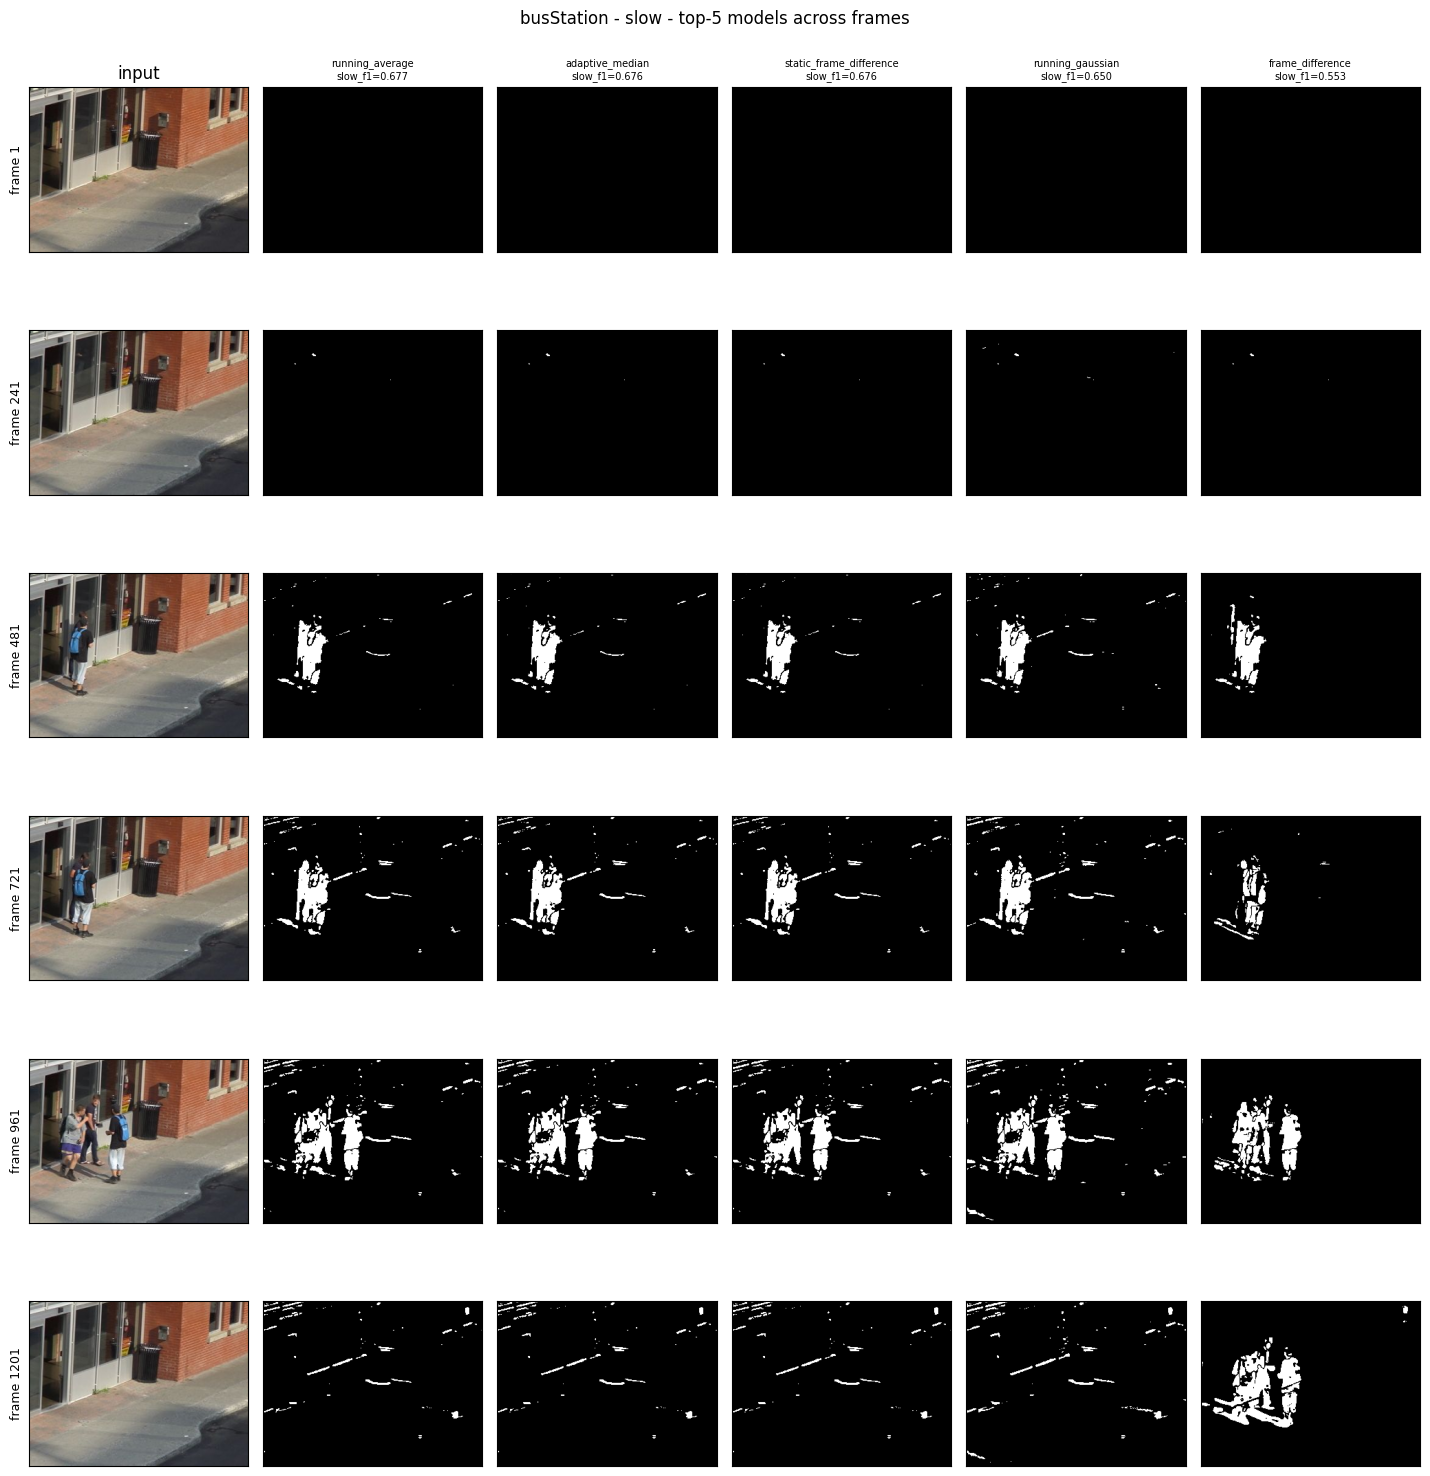

In [41]:
show_grid('busStation', 'slow')

### Grid 2 — busStation, fast

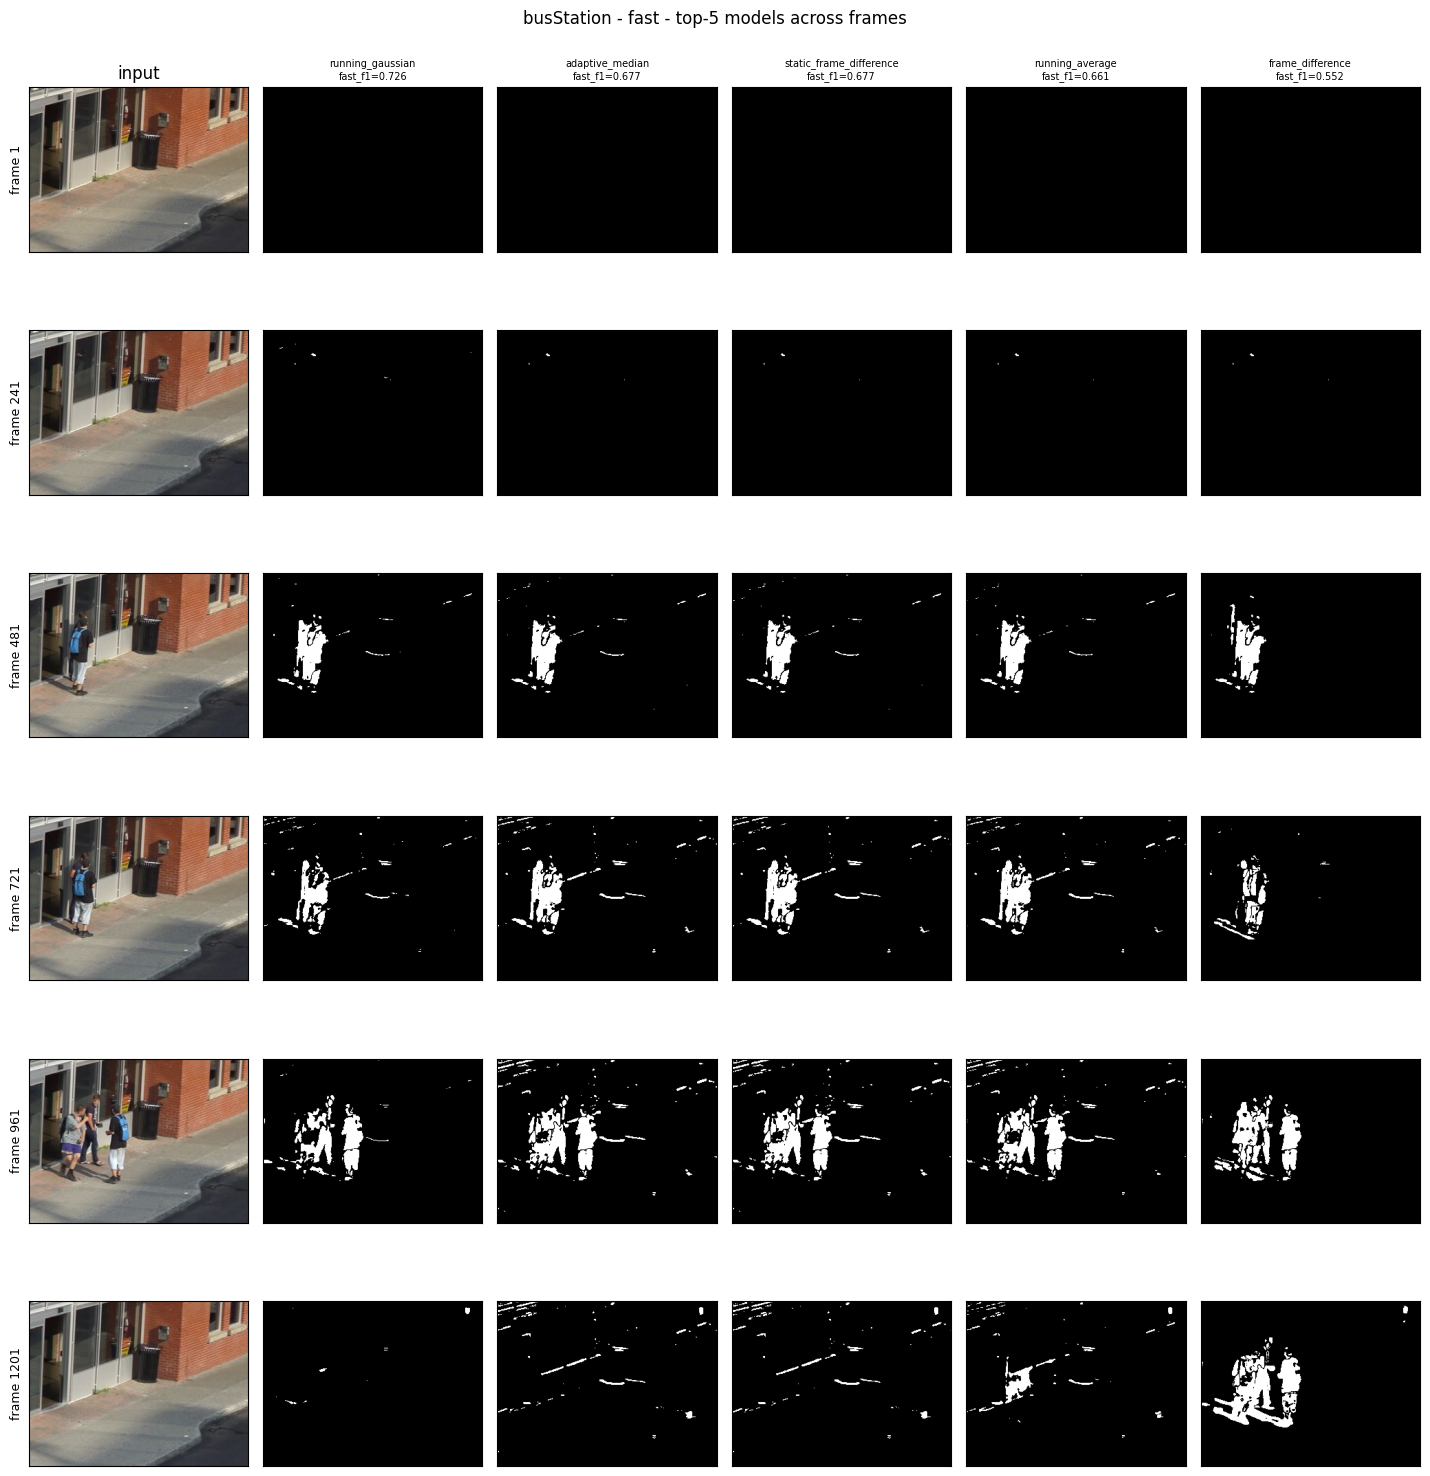

In [42]:
show_grid('busStation', 'fast')

### Grid 3 — canoe, slow

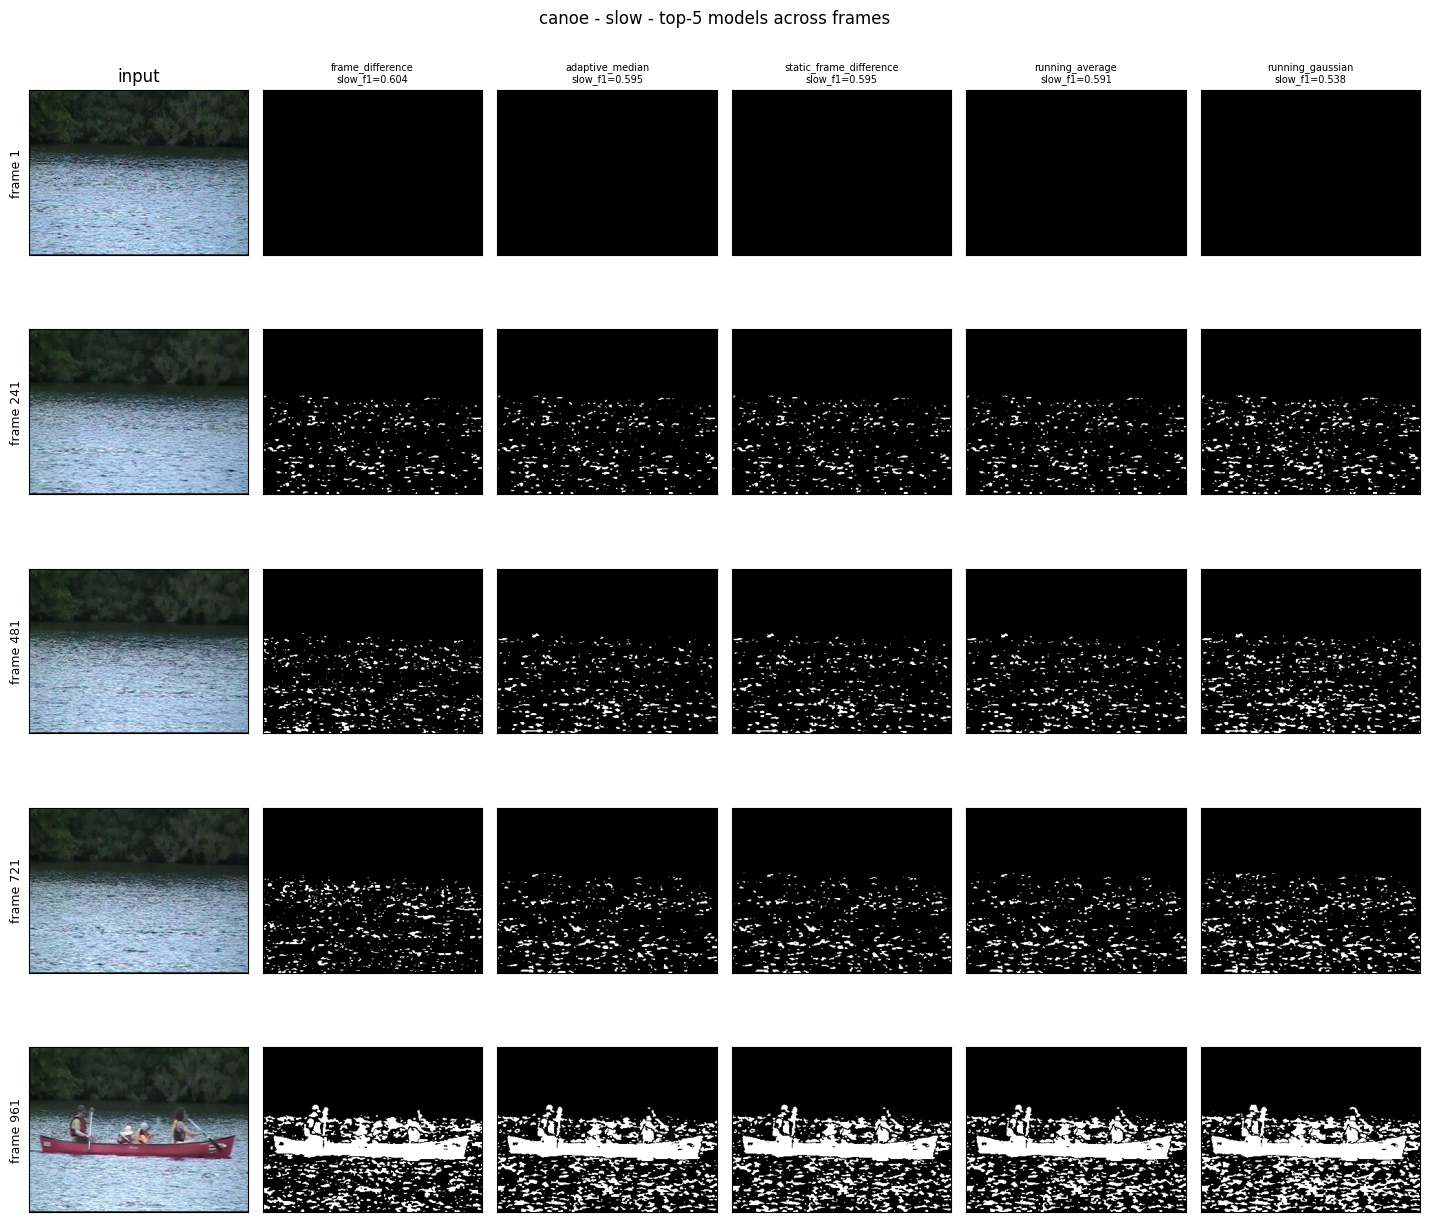

In [43]:
show_grid('canoe', 'slow')

### Grid 4 — canoe, fast

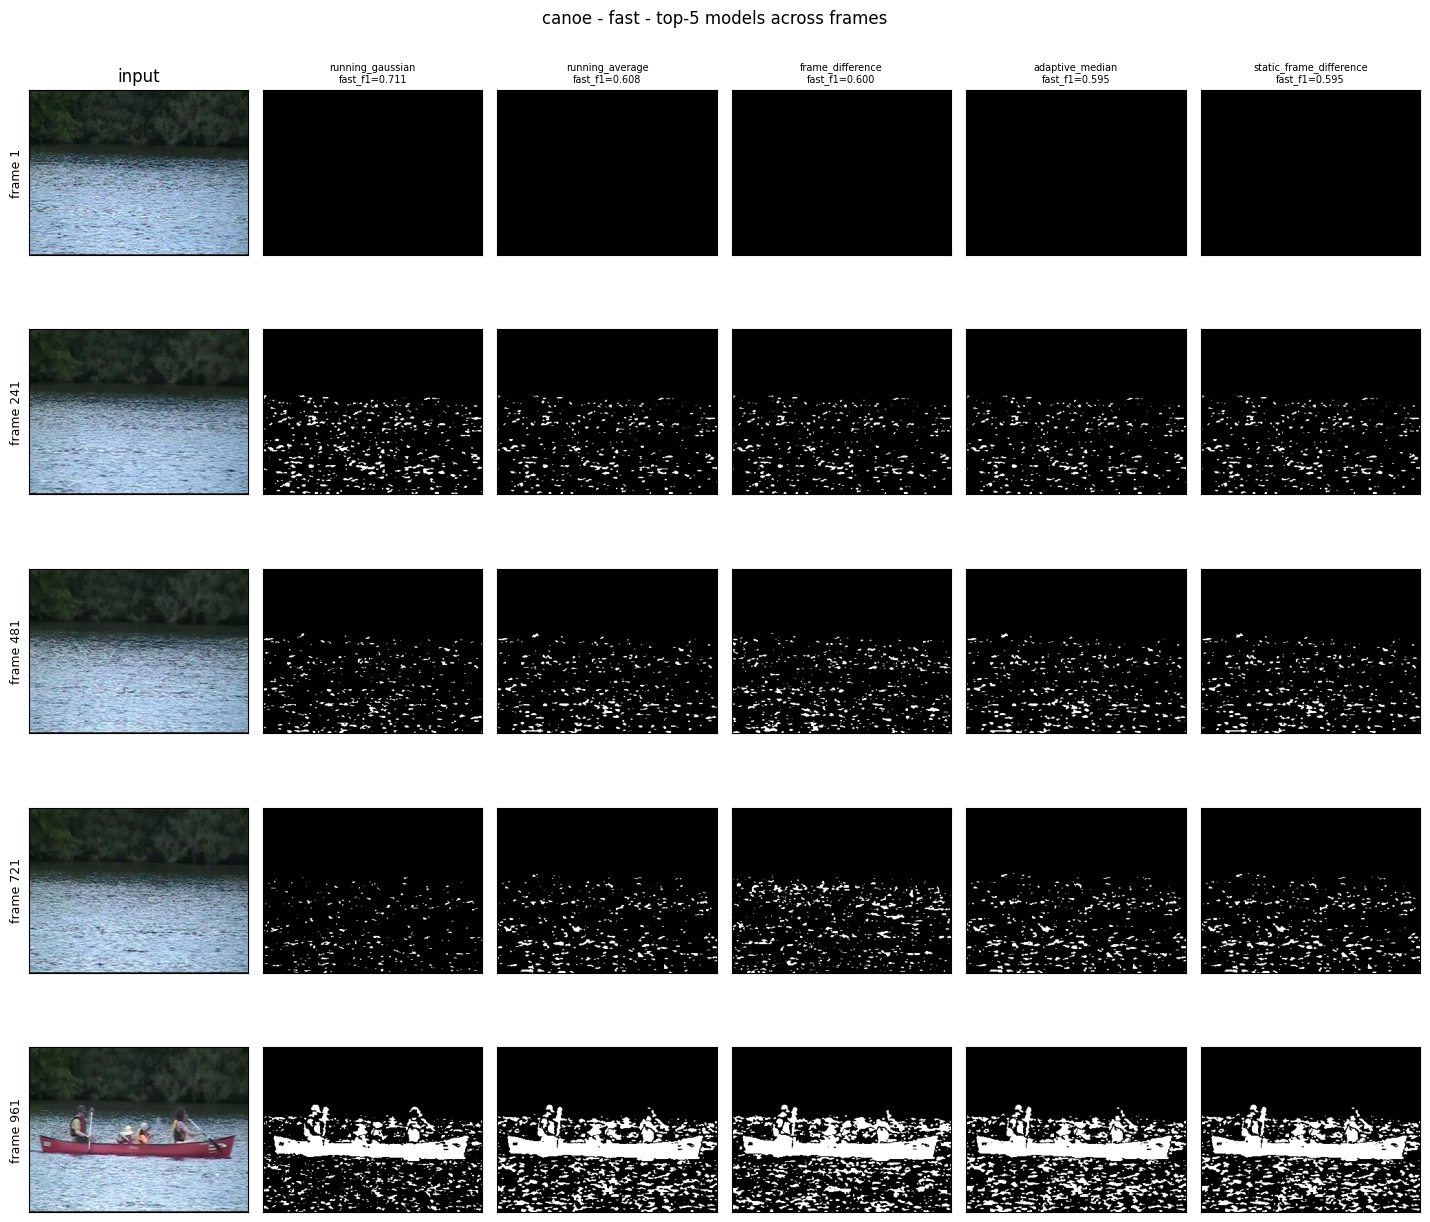

In [44]:
show_grid('canoe', 'fast')

## 4. Static-candidate grids — `slow AND NOT fast`

For each case: the input frame followed by each model's **static candidate** `slow_mask AND NOT fast_mask` — the dual-rate left-object cue. It is computed here from each model's diagonal `M__M` masks (slow model at alpha=0.001 AND NOT fast model at alpha=0.1), i.e. pixels the slow model still holds but the fast model has already absorbed. Two grids, one row per frame.

In [45]:
def load_static(model, case, frame):
    """Static candidate = slow mask AND NOT fast mask, for a model's diagonal pair."""
    slow = load_mask(model, 'slow', case, frame) > 0
    fast = load_mask(model, 'fast', case, frame) > 0
    return (slow & ~fast).astype(np.uint8) * 255


def show_static_grid(case):
    """Grid for a case: each row a frame, cols = input + top-N models' static candidate."""
    frames = all_frames(case)
    ranked = top_models(case, 'slow')
    models = [model for model, _ in ranked]
    columns = 1 + len(models)
    fig, axes = plt.subplots(
        len(frames), columns, figsize=(2.4 * columns, 2.6 * len(frames))
    )
    axes = axes.reshape(len(frames), columns)
    for row, frame in enumerate(frames):
        axes[row, 0].imshow(load_input(case, frame))
        axes[row, 0].set_ylabel(f'frame {frame}', fontsize=9)
        if row == 0:
            axes[row, 0].set_title('input')
        for column, model in enumerate(models, start=1):
            axes[row, column].imshow(
                load_static(model, case, frame), cmap='gray', vmin=0, vmax=255
            )
            if row == 0:
                axes[row, column].set_title(f'{model}\nslow AND NOT fast', fontsize=6)
        for column in range(columns):
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])
    fig.suptitle(f'{case} - static candidate (slow AND NOT fast) - top-{TOP_N} models')
    plt.tight_layout()
    plt.show()

### Grid 5 — busStation, static candidate

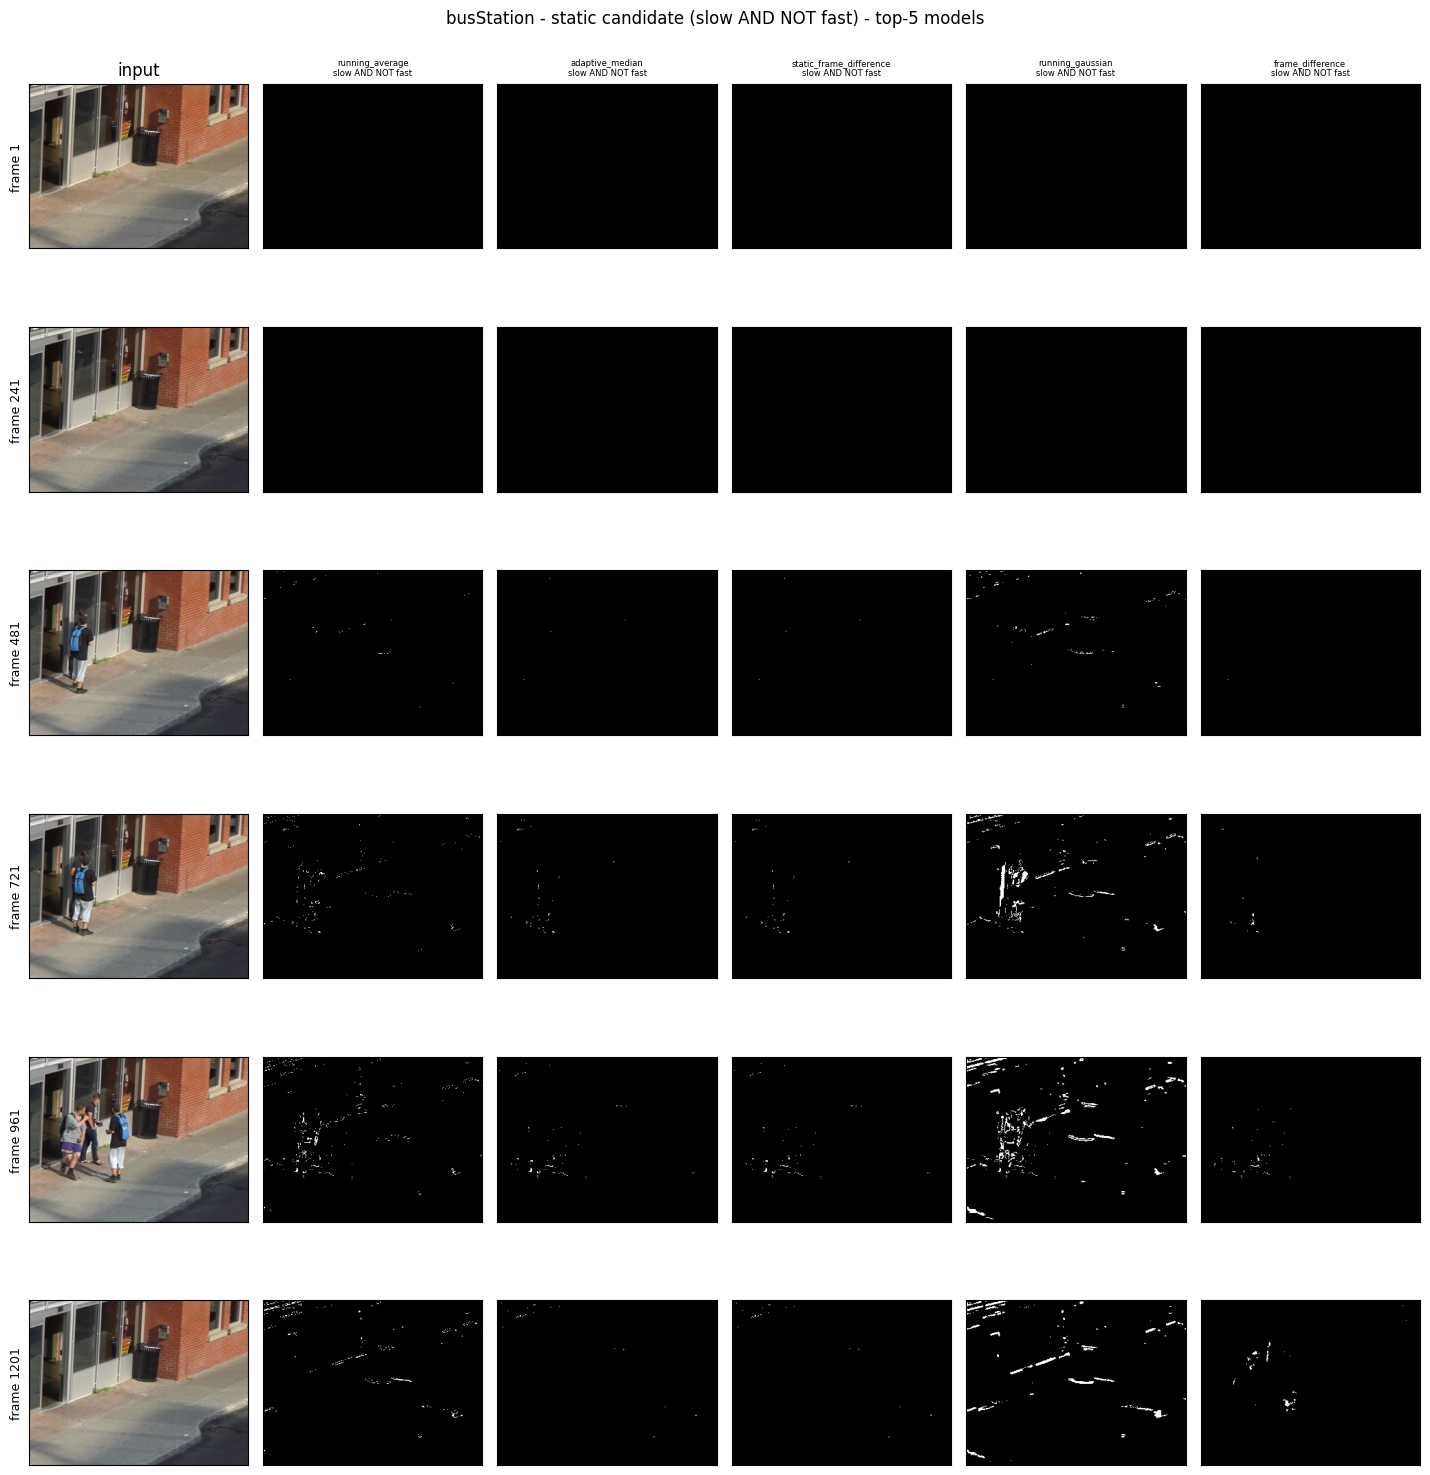

In [46]:
show_static_grid('busStation')

### Grid 6 — canoe, static candidate

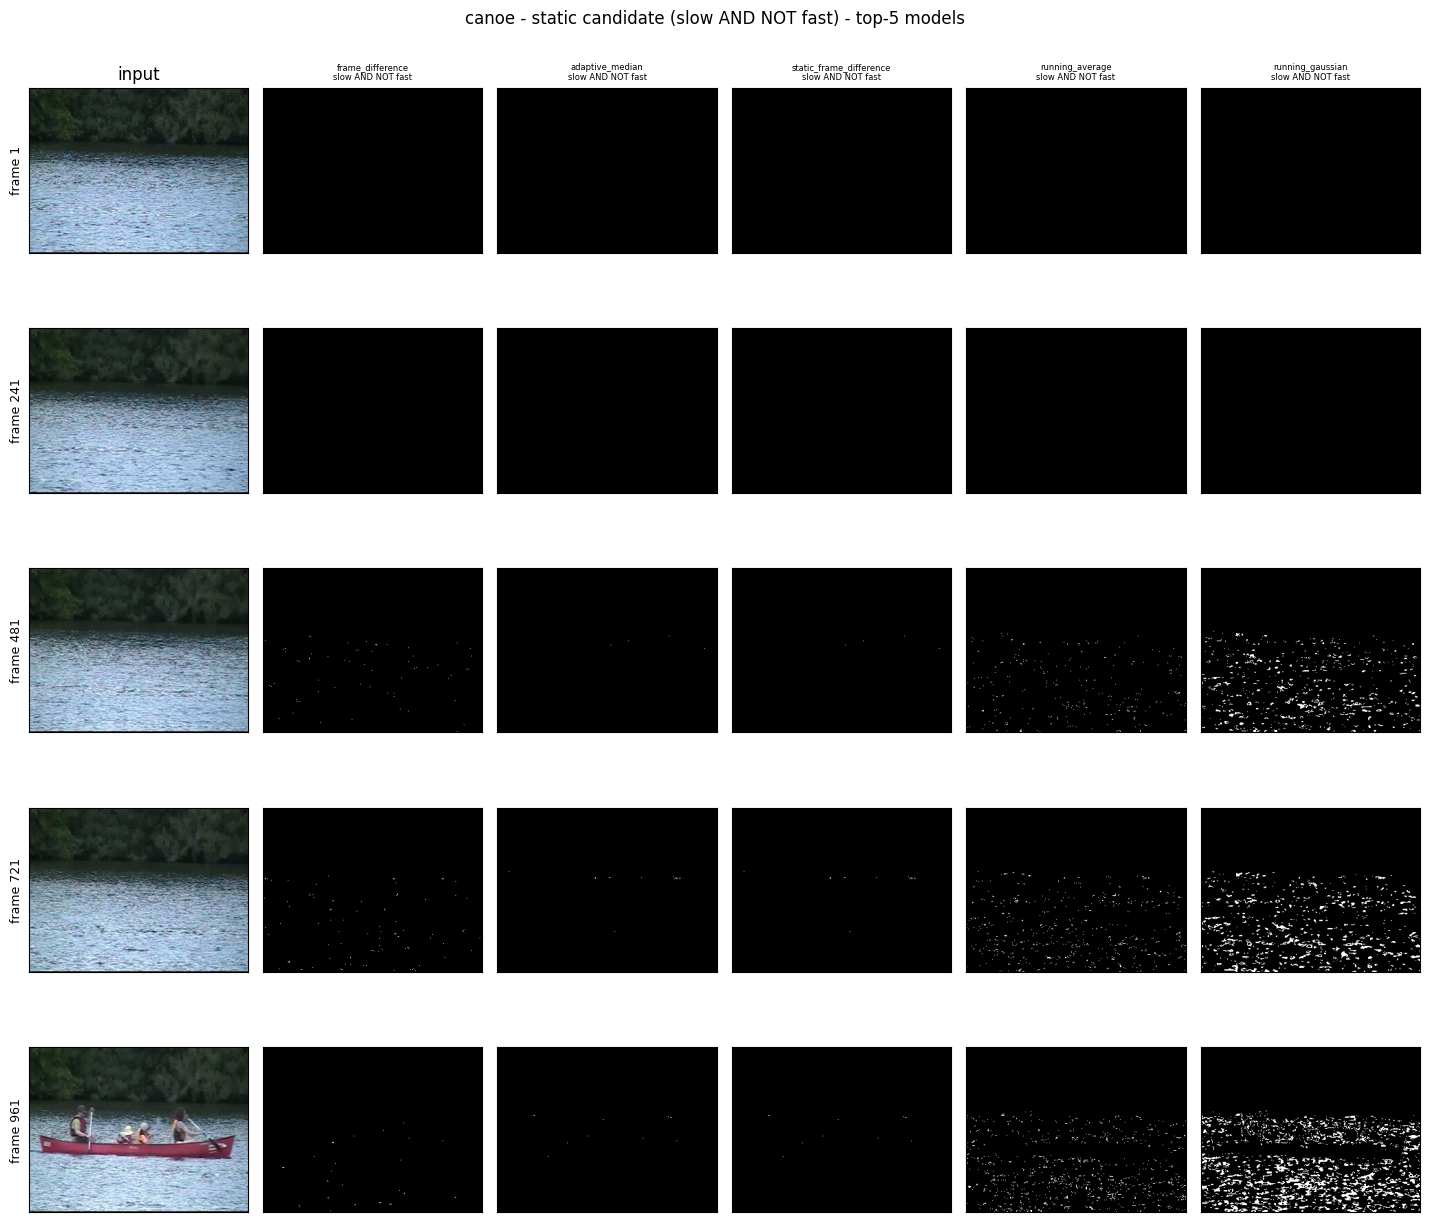

In [47]:
show_static_grid('canoe')